# WattWise Grocery Store Energy Analysis

Run the cells from top to bottom. The dataset should be available at `data/adrenalin.1h.L07.B01.EM01.P.csv`, relative to the notebook's working directory.

## Imports

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,r2_score
from sklearn.ensemble import RandomForestRegressor

## 1. Load the dataset

In [86]:
df_electricity = pd.read_csv(
    "../data/adrenalin.1h.L07.B01.EM01.P.csv"
)

## 2. Inspect the raw data

In [87]:
print(df_electricity.head())
print(df_electricity.columns)
print(df_electricity.shape)

df_electricity.info()

        timestamp [UTC]  value P [Total active power (kW)]
0  2021-11-29T06:00:00Z                          52.400002
1  2021-11-29T07:00:00Z                          69.812500
2  2021-11-29T08:00:00Z                          55.779167
3  2021-11-29T09:00:00Z                          55.187879
4  2021-11-29T10:00:00Z                          54.813333
Index(['timestamp [UTC]', 'value P [Total active power (kW)]'], dtype='str')
(9546, 2)
<class 'pandas.DataFrame'>
RangeIndex: 9546 entries, 0 to 9545
Data columns (total 2 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   timestamp [UTC]                    9546 non-null   str    
 1   value P [Total active power (kW)]  9546 non-null   float64
dtypes: float64(1), str(1)
memory usage: 335.7 KB


## 3. Convert timestamp to datetime

In [88]:
df_electricity["timestamp [UTC]"] = pd.to_datetime(
    df_electricity["timestamp [UTC]"]
)

## 4. Rename columns

In [89]:
df_electricity = df_electricity.rename(columns={
    "timestamp [UTC]": "timestamp",
    "value P [Total active power (kW)]": "power_kw"
})

## 5. Check data quality

In [90]:
print("Start:", df_electricity["timestamp"].min())
print("End:", df_electricity["timestamp"].max())

print("Zero values:", (df_electricity["power_kw"] == 0).sum())
print("Negative values:", (df_electricity["power_kw"] < 0).sum())

print("Minimum power:", df_electricity["power_kw"].min())
print("Maximum power:", df_electricity["power_kw"].max())

Start: 2021-11-29 06:00:00+00:00
End: 2022-12-31 23:00:00+00:00
Zero values: 0
Negative values: 0
Minimum power: 26.193023060643394
Maximum power: 93.13181851126932


## 6. Check hourly continuity

In [91]:
time_diff = df_electricity["timestamp"].diff()

print(time_diff.value_counts())

timestamp
0 days 01:00:00    9545
Name: count, dtype: int64


## 7. Convert UTC to local Norway time

In [92]:
df_electricity["local_timestamp"] = (
    df_electricity["timestamp"]
    .dt.tz_convert("Europe/Oslo")
)

## 8. Create time features

In [93]:
df_electricity["hour"] = (
    df_electricity["local_timestamp"].dt.hour
)

df_electricity["day_of_week"] = (
    df_electricity["local_timestamp"].dt.day_name()
)

df_electricity["weekend"] = (
    df_electricity["day_of_week"]
    .isin(["Saturday", "Sunday"])
)

## 9. Analyze average power by hour

In [94]:
average_by_hour = (
    df_electricity
    .groupby("hour")["power_kw"]
    .mean()
)

print("Peak hour:", average_by_hour.idxmax())
print("Peak average power:", average_by_hour.max())

print("Lowest hour:", average_by_hour.idxmin())
print("Lowest average power:", average_by_hour.min())

Peak hour: 7
Peak average power: 67.80766983844546
Lowest hour: 4
Lowest average power: 34.50600305429886


## 10. Compare weekday vs weekend

In [95]:
average_by_weekend = (
    df_electricity
    .groupby("weekend")["power_kw"]
    .mean()
)

print(average_by_weekend)

weekend
False    51.568577
True     42.200628
Name: power_kw, dtype: float64


## 11. Look at first 7 full days

In [96]:
first_seven_days = df_electricity[
    (df_electricity["timestamp"] >= "2021-11-29 06:00:00+00:00") &
    (df_electricity["timestamp"] < "2021-12-06 06:00:00+00:00")
]

print(first_seven_days.shape)

(168, 6)


## 12. Plot first 7 days

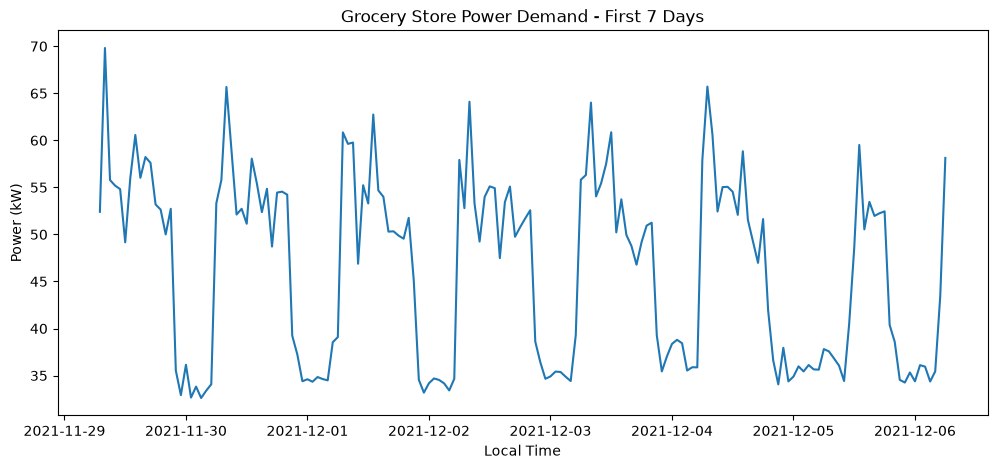

In [97]:
plt.figure(figsize=(12, 5))

plt.plot(
    first_seven_days["local_timestamp"],
    first_seven_days["power_kw"]
)

plt.title("Grocery Store Power Demand - First 7 Days")
plt.xlabel("Local Time")
plt.ylabel("Power (kW)")

plt.show()

## 13. Average Power by Hour: Weekday vs Weekend

hour  weekend
0     False      34.990799
      True       34.704866
1     False      35.374807
      True       35.158123
2     False      35.293615
      True       35.345793
3     False      34.185710
      True       36.926725
4     False      34.238631
      True       35.177983
5     False      40.136695
      True       37.531639
6     False      54.279999
      True       42.753869
7     False      72.490625
      True       55.996677
8     False      67.920721
      True       50.352438
9     False      61.484646
      True       46.807299
10    False      59.476290
      True       45.573495
11    False      60.493068
      True       45.717672
12    False      60.461623
      True       47.315629
13    False      62.117753
      True       49.826607
14    False      61.881673
      True       48.477453
15    False      60.044685
      True       46.540964
16    False      57.541555
      True       45.056104
17    False      57.213643
      True       45.119640
18    False   

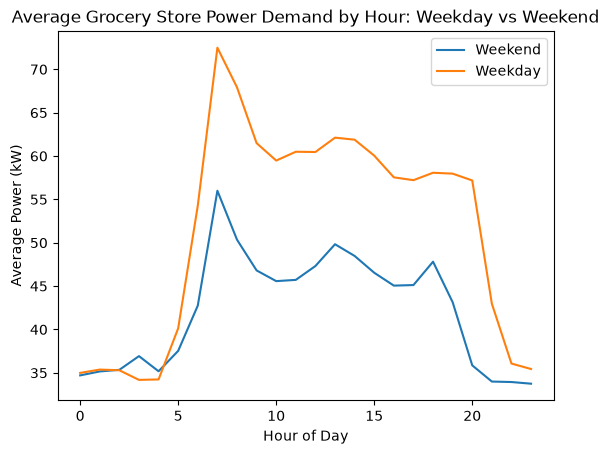

In [98]:
average_by_hour_weekend = (
    df_electricity
    .groupby(["hour","weekend"]).power_kw.mean()
)
print(average_by_hour_weekend)

average_by_hour_weekend = average_by_hour_weekend.unstack()


x = average_by_hour_weekend.index
weekend = average_by_hour_weekend[True]
weekday = average_by_hour_weekend[False]

plt.plot(x, weekend, label="Weekend")
plt.plot(x, weekday, label="Weekday")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power (kW)")
plt.title("Average Grocery Store Power Demand by Hour: Weekday vs Weekend")
plt.legend()
plt.show()

The graph shows that average power demand is lower on weekends than on weekdays, 
especially from around 5 AM through the evening. Overnight, weekday and weekend power demand are much more similar.

## 14. Check Pattern Differences Between Months

In [99]:
df_electricity["month"] = df_electricity["local_timestamp"].dt.month

print(df_electricity.month)


average_by_month = df_electricity.groupby("month").power_kw.mean()

print(average_by_month)

0       11
1       11
2       11
3       11
4       11
        ..
9541    12
9542    12
9543    12
9544    12
9545     1
Name: month, Length: 9546, dtype: int32
month
1     45.491232
2     46.441801
3     47.641564
4     45.799281
5     46.498435
6     52.901944
7     53.390540
8     57.080910
9     49.932840
10    46.656305
11    48.288856
12    47.749974
Name: power_kw, dtype: float64


## 15. Prepare Features and Target

In [100]:
X = df_electricity[["hour","weekend","month"]]
y = df_electricity["power_kw"]

print(X.shape)

print(X.head())
print(y.head())

(9546, 3)
   hour  weekend  month
0     7    False     11
1     8    False     11
2     9    False     11
3    10    False     11
4    11    False     11
0    52.400002
1    69.812500
2    55.779167
3    55.187879
4    54.813333
Name: power_kw, dtype: float64


## 16. Split Training and Test Data

In [101]:
split_index = int(len(df_electricity) * 0.8)

print(split_index)
print(len(df_electricity))

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print(X_train.shape)

print(X_test.shape)

print(y_train.shape)

print(y_test.shape)

7636
9546
(7636, 3)
(1910, 3)
(7636,)
(1910,)


## 17. Train Linear Regression

In [102]:
model = LinearRegression()

model.fit(X=X_train,y=y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.32,-9.13, 0.37]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['hour','weekend','month']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,45.78
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


## 18. Generate Predictions

In [103]:
y_pred = model.predict(X_test)

print(y_pred[:5])
print(y_test.head())

[53.34526258 53.66760564 53.98994869 54.31229175 54.6346348 ]
7636    68.690698
7637    60.853333
7638    64.202326
7639    62.624390
7640    55.757778
Name: power_kw, dtype: float64


Finding the Mean Absolute Error to establish a baseline

In [104]:
mae = mean_absolute_error(y_test,y_pred)

print(mae)

11.591523873209097


In [105]:
print(y_test.mean())

48.148749278136926


Baseline Linear Regression
Features: hour, weekend, month
Test MAE: 11.59 kW
Average test demand: 48.15 kW

In [106]:
print(r2_score(y_test,y_pred))

0.08544713284217798


Baseline model results:
Linear Regression using hour, weekend, and month produced an MAE of 11.59 kW and an R² of 0.085. This indicates that the model captures only a small portion of the variation in grocery-store power demand.

In [107]:
rf_model = RandomForestRegressor(random_state=42)

In [108]:
rf_model.fit(X=X_train, y=y_train)

rf_pred = rf_model.predict(X_test)
print(rf_pred[:5])
print(y_test.head())

[58.7254738  61.33778166 61.97912271 58.38091823 59.2565996 ]
7636    68.690698
7637    60.853333
7638    64.202326
7639    62.624390
7640    55.757778
Name: power_kw, dtype: float64


In [109]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print(rf_mae)
print(rf_r2)

5.694873237625087
0.6767539628842554


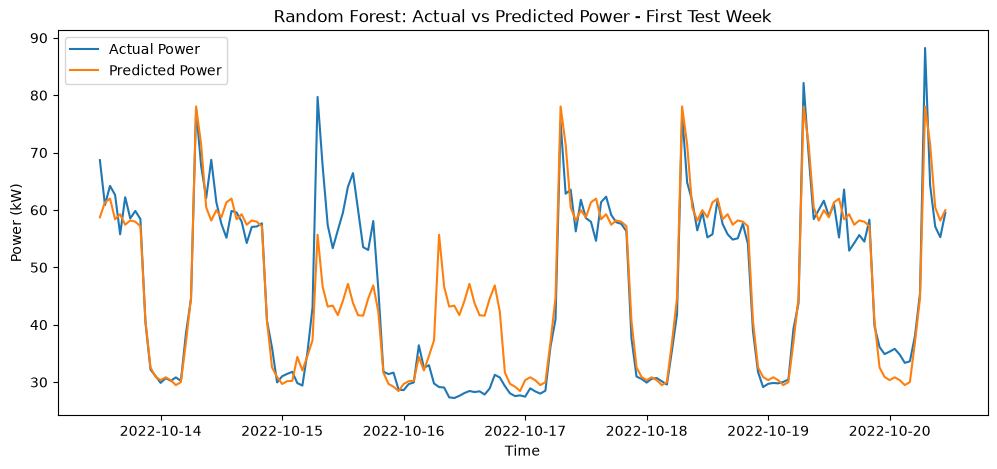

In [110]:
test_timestamps = df_electricity["local_timestamp"].iloc[split_index:]

plt.figure(figsize=(12, 5))

plt.plot(
    test_timestamps.iloc[:168],
    y_test.iloc[:168],
    label="Actual Power"
)

plt.plot(
    test_timestamps.iloc[:168],
    rf_pred[:168],
    label="Predicted Power"
)

plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title("Random Forest: Actual vs Predicted Power - First Test Week")
plt.legend()
plt.show()

In [111]:
rf_error = abs(y_test - rf_pred)

print(rf_error.head())

7636    9.965224
7637    0.484448
7638    2.223203
7639    4.243472
7640    3.498822
Name: power_kw, dtype: float64


In [112]:
largest_errors = rf_error.sort_values(ascending=False)
print(largest_errors.head())

8856    36.985653
8280    30.140453
9024    28.747521
8496    27.267726
8494    26.761601
Name: power_kw, dtype: float64


In [113]:
rf_pred_series = pd.Series(rf_pred, index=y_test.index)

In [114]:
print(df_electricity.loc[8856, "local_timestamp"])
print(y_test.loc[8856])
print(rf_pred_series.loc[8856])
print(rf_error.loc[8856])

2022-12-03 07:00:00+01:00
85.71590961109509
48.730256617444
36.98565299365109


In [115]:
error_index = 8856

surrounding_hours = df_electricity.loc[
    error_index - 6:error_index + 6,
    ["local_timestamp", "power_kw"]
]

print(surrounding_hours)

               local_timestamp   power_kw
8850 2022-12-03 01:00:00+01:00  35.848837
8851 2022-12-03 02:00:00+01:00  34.953333
8852 2022-12-03 03:00:00+01:00  34.679546
8853 2022-12-03 04:00:00+01:00  33.609091
8854 2022-12-03 05:00:00+01:00  38.148837
8855 2022-12-03 06:00:00+01:00  53.159091
8856 2022-12-03 07:00:00+01:00  85.715910
8857 2022-12-03 08:00:00+01:00  68.460000
8858 2022-12-03 09:00:00+01:00  62.283721
8859 2022-12-03 10:00:00+01:00  57.995349
8860 2022-12-03 11:00:00+01:00  59.304444
8861 2022-12-03 12:00:00+01:00  63.634091
8862 2022-12-03 13:00:00+01:00  66.220930


In [116]:
print("Linear Regression MAE:", mae)
print("Linear Regression R²:", r2_score(y_test, y_pred))

print("Random Forest MAE:", rf_mae)
print("Random Forest R²:", rf_r2)

Linear Regression MAE: 11.591523873209097
Linear Regression R²: 0.08544713284217798
Random Forest MAE: 5.694873237625087
Random Forest R²: 0.6767539628842554


In [117]:
similar_hours = df_electricity.loc[X_train.index]

similar_hours = similar_hours[
    (similar_hours["hour"] == 7) &
    (similar_hours["weekend"] == True) &
    (similar_hours["month"] == 12)
]

print("Number of similar observations:", len(similar_hours))

print("Average power:", similar_hours["power_kw"].mean())

print("Maximum power:", similar_hours["power_kw"].max())

print("Actual power at observation 8856:", y_test.loc[8856])

print("Random Forest prediction:", rf_pred_series.loc[8856])

Number of similar observations: 8
Average power: 47.891212940972146
Maximum power: 75.57045433738016
Actual power at observation 8856: 85.71590961109509
Random Forest prediction: 48.730256617444


In [118]:
df_lag = df_electricity.sort_values("timestamp").copy()

df_lag["lag_1h"] = df_lag["power_kw"].shift(1)

valid_previous_hour = (
    df_lag["timestamp"].diff() == pd.Timedelta(hours=1)
)

df_lag.loc[~valid_previous_hour, "lag_1h"] = float("nan")

print(
    df_lag.loc[
        [8855, 8856, 8857],
        ["local_timestamp", "power_kw", "lag_1h"]
    ]
)

print(
    "Missing previous-hour values:",
    df_lag["lag_1h"].isna().sum()
)

               local_timestamp   power_kw     lag_1h
8855 2022-12-03 06:00:00+01:00  53.159091  38.148837
8856 2022-12-03 07:00:00+01:00  85.715910  53.159091
8857 2022-12-03 08:00:00+01:00  68.460000  85.715910
Missing previous-hour values: 1


## 21. Preparing to Train Your Improved Model

In [119]:
df_lag = df_lag.dropna(subset="lag_1h")

In [120]:
X = df_lag[["hour","month","weekend","lag_1h"]]

y = df_lag["power_kw"]

## 22. Splitting data

In [121]:
split_index = int(len(df_lag) * 0.8)

In [122]:
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [123]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(7636, 4)
(1909, 4)
(7636,)
(1909,)


In [125]:
rf_w_lag_model = RandomForestRegressor(random_state=42) 

rf_w_lag_model.fit(X=X_train, y=y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

## 24. Predict with lag

In [127]:
rf_w_lag_pred = rf_w_lag_model.predict(X_test)

print(rf_w_lag_pred[:5])
print(y_test.head())

[60.3191006  61.75980788 56.8947186  58.79354458 56.57127546]
7637    60.853333
7638    64.202326
7639    62.624390
7640    55.757778
7641    62.229546
Name: power_kw, dtype: float64


In [129]:
mae_w_lag = mean_absolute_error(y_test,rf_w_lag_pred )
r2_score_w_lag = r2_score(y_test,rf_w_lag_pred )

print(mae_w_lag)
print(r2_score_w_lag)

3.2566234785774726
0.8709824674090614


In [133]:

X_train_original = X_train[["hour","month","weekend"]]

X_test_original = X_test[["hour","month","weekend"]]

In [134]:
original_ft_rf = RandomForestRegressor(random_state=42)

original_ft_rf.fit(X_train_original,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [136]:
original_ft_rf_pred = original_ft_rf.predict(X_test_original)

original_mae_w_lag = mean_absolute_error(y_test,original_ft_rf_pred )
original_r2_score_w_lag = r2_score(y_test,original_ft_rf_pred)

print(original_mae_w_lag)
print(original_r2_score_w_lag)

5.6506838269471755
0.6840562862346643


In [140]:
original_rf_w_lag_error = abs(y_test - original_ft_rf_pred)

In [141]:
rf_w_lag_error = abs(y_test - rf_w_lag_pred)

In [138]:
rf_pred_w_lag_series = pd.Series(rf_w_lag_pred, index=y_test.index)

print(df_electricity.loc[8856, "local_timestamp"])
print(y_test.loc[8856])
print(rf_pred_w_lag_series.loc[8856])
print(rf_w_lag_error.loc[8856])

2022-12-03 07:00:00+01:00
85.71590961109509
62.18941553591324
38.50418697847993


In [144]:

print(original_rf_w_lag_error.head())
print(rf_w_lag_error.head())

print(original_rf_w_lag_error.shape)
print(rf_w_lag_error.shape)

#abs_error_series = pd.Series([rf_w_lag_error,original_rf_w_lag_error])

#print(abs_error_series)


7637    0.703107
7638    2.334276
7639    4.444629
7640    3.320605
7641    4.848367
Name: power_kw, dtype: float64
7637    0.534233
7638    2.442518
7639    5.729672
7640    3.035767
7641    5.658270
Name: power_kw, dtype: float64
(1909,)
(1909,)
